In [2]:
import os

for root, dirs , files in os.walk("/kaggle/input"):
    print(root)

    if files:
        print(" Files:", files[:5])

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/prateekagrawalcodes
/kaggle/input/datasets/prateekagrawalcodes/deep-learning
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 4 - Self Organizing Maps (SOM)
 Files: ['Credit_Card_Applications.csv']
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 3 - Recurrent Neural Networks (RNN)
 Files: ['Google_Stock_Price_Test.csv', 'Google_Stock_Price_Train.csv']
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 5 - Boltzmann Machines (BM)
 Files: ['AItRBM-proof.pdf']
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 5 - Boltzmann Machines (BM)/ml-1m
 Files: ['Train_Test_Set_Creation.R', 'test_set.csv', 'ratings.csv', 'users.dat', 'ratings.dat']
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 5 - Boltzmann Machines (BM)/ml-100k
 Files: ['u.occupation', 'u1.base', 'u.info', 'u4.test', 'u.item']
/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 2 - Convolutional Ne

In [3]:
import os

dataset_path = "/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 2 - Convolutional Neural Networks (CNN)/dataset"

train_path = os.path.join(dataset_path, "training_set")
test_path = os.path.join(dataset_path, "test_set")

print("Training set:")
print("Cats:", len(os.listdir(os.path.join(train_path, "cats"))))
print("Dogs:", len(os.listdir(os.path.join(train_path, "dogs"))))

print("\nTest set:")
print("Cats:", len(os.listdir(os.path.join(test_path, "cats"))))
print("Dogs:", len(os.listdir(os.path.join(test_path, "dogs"))))

Training set:
Cats: 4000
Dogs: 4000

Test set:
Cats: 1000
Dogs: 1000


In [4]:
import torch
from torchvision import datasets

dataset_path = "/kaggle/input/datasets/prateekagrawalcodes/deep-learning/Part 2 - Convolutional Neural Networks (CNN)/dataset"

train_path = dataset_path + "/training_set"
test_path = dataset_path + "/test_set"

train_dataset = datasets.ImageFolder(train_path)
test_dataset = datasets.ImageFolder(test_path)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

Training images: 8000
Test images: 2000
Classes: ['cats', 'dogs']
Class mapping: {'cats': 0, 'dogs': 1}


In [5]:
import torch
from torchvision import datasets, transforms
train_transform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean = [0.5, 0.5, 0.5],
        std = [0.5, 0.5, 0.5]
    )
])

In [6]:
test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [7]:
train_dataset = datasets.ImageFolder(
    train_path, transform = train_transform
)
test_dataset = datasets.ImageFolder(
    test_path, transform = test_transform
)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)


Training images: 8000
Test images: 2000
Classes: ['cats', 'dogs']
Class mapping: {'cats': 0, 'dogs': 1}


In [8]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size = 32,
    shuffle = True
)
test_loader = DataLoader(
    test_dataset,
    batch_size = 32,
    shuffle = False
)
print("Number of training batches:", len(train_loader))
print("Number of test batches:", len(test_loader))

Number of training batches: 250
Number of test batches: 63


In [9]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 64, 64])
Label batch shape: torch.Size([32])
Labels: tensor([1, 0, 1, 0, 0, 1, 0, 1, 1, 0])


import torch.nn as nn

# Example: 3 input channels (RGB), 16 output channels, 3x3 filter size
conv_layer = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)


In [10]:
import torch.nn as nn

class CatDogCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),

            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),

            nn.Conv2d(64, 128, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CatDogCNN()
print(model)

CatDogCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [11]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda:0


In [12]:
model = model.to(device)

print("Model is on:", next(model.parameters()).device)

Model is on: cuda:0


In [13]:
import torch.nn as nn
import torch.optim as optim

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr = 0.001
)

print("Loss function:", criterion)
print("optimizer:", optimizer)

Loss function: BCEWithLogitsLoss()
optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [14]:
from torch.utils.data import random_split, Subset

# Original 8000 training images
full_train_dataset = datasets.ImageFolder(train_path)

# 80% train, 20% validation
train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

# Fixed seed so split remains the same
generator = torch.Generator().manual_seed(42)

train_subset, val_subset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=generator
)

# Training dataset → augmentation enabled
train_dataset = Subset(
    datasets.ImageFolder(train_path, transform=train_transform),
    train_subset.indices
)

# Validation dataset → NO augmentation
val_dataset = Subset(
    datasets.ImageFolder(train_path, transform=test_transform),
    val_subset.indices
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 6400
Validation images: 1600


In [15]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 200
Validation batches: 50


Epoch [1/15] | Train Loss: 0.6686 | Train Acc: 58.55% | Val Loss: 0.6288 | Val Acc: 64.62%
Epoch [2/15] | Train Loss: 0.5846 | Train Acc: 68.67% | Val Loss: 0.5768 | Val Acc: 70.50%
Epoch [3/15] | Train Loss: 0.5429 | Train Acc: 72.44% | Val Loss: 0.5449 | Val Acc: 73.25%
Epoch [4/15] | Train Loss: 0.5046 | Train Acc: 75.23% | Val Loss: 0.5111 | Val Acc: 75.00%


KeyboardInterrupt: 

In [17]:

import os
import torch

# Training settings
epochs = 30
patience = 5
best_val_loss = float("inf")
epochs_without_improvement = 0

# Folder to save checkpoints
save_dir = "/kaggle/working/cat_dog_checkpoints"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(save_dir, "best_model.pth")

for epoch in range(epochs):

    # ========== TRAINING ==========
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = (outputs >= 0).float()
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    # ========== VALIDATION ==========
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().to(device).unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = (outputs >= 0).float()
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # ========== SAVE BEST MODEL ==========
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), best_model_path)

        print(f"  Best model saved! Val Loss: {best_val_loss:.4f}")

    else:
        epochs_without_improvement += 1

    # ========== SAVE EVERY 10 EPOCHS ==========
    if (epoch + 1) % 10 == 0:

        checkpoint_path = os.path.join(
            save_dir, f"checkpoint_epoch_{epoch + 1}.pth"
        )

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss,
            "val_accuracy": val_accuracy
        }, checkpoint_path)

        print(f"  Checkpoint saved: {checkpoint_path}")

    # ========== EARLY STOPPING ==========
    if epochs_without_improvement >= patience:

        print(
            f"\nEarly stopping at epoch {epoch + 1}. "
            f"Validation loss did not improve for {patience} epochs."
        )
        break

print("\nTraining finished.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model location: {best_model_path}")

Epoch [1/30] | Train Loss: 0.4583 | Train Acc: 77.98% | Val Loss: 0.4691 | Val Acc: 78.81%
  Best model saved! Val Loss: 0.4691
Epoch [2/30] | Train Loss: 0.4390 | Train Acc: 79.69% | Val Loss: 0.4588 | Val Acc: 78.62%
  Best model saved! Val Loss: 0.4588
Epoch [3/30] | Train Loss: 0.4209 | Train Acc: 80.75% | Val Loss: 0.4569 | Val Acc: 78.81%
  Best model saved! Val Loss: 0.4569
Epoch [4/30] | Train Loss: 0.3996 | Train Acc: 82.55% | Val Loss: 0.4557 | Val Acc: 78.69%
  Best model saved! Val Loss: 0.4557
Epoch [5/30] | Train Loss: 0.3869 | Train Acc: 82.34% | Val Loss: 0.4324 | Val Acc: 79.56%
  Best model saved! Val Loss: 0.4324
Epoch [6/30] | Train Loss: 0.3736 | Train Acc: 83.30% | Val Loss: 0.4284 | Val Acc: 80.69%
  Best model saved! Val Loss: 0.4284
Epoch [7/30] | Train Loss: 0.3523 | Train Acc: 84.78% | Val Loss: 0.4362 | Val Acc: 81.44%
Epoch [8/30] | Train Loss: 0.3457 | Train Acc: 84.77% | Val Loss: 0.4602 | Val Acc: 79.44%
Epoch [9/30] | Train Loss: 0.3334 | Train Acc: 85.

In [18]:
model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

model.to(device)
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [ ]:

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        64,
        scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5, 0.5, 0.5],
        std=[0.5, 0.5, 0.5]
    )
])

In [19]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets

# Recreate datasets using the updated transforms
train_dataset = Subset(
    datasets.ImageFolder(
        train_path,
        transform=train_transform
    ),
    train_subset.indices
)

val_dataset = Subset(
    datasets.ImageFolder(
        train_path,
        transform=test_transform
    ),
    val_subset.indices
)

# Recreate DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# Verify dataset sizes
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training images: 6400
Validation images: 1600
Training batches: 200
Validation batches: 50


In [20]:
import torch
import torch.nn as nn
import torch.optim as optim

# Create a fresh model
model = CatDogCNN().to(device)

# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Create a fresh optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Verify model
print("Device:", device)
print("Model initialized from scratch!")
print("Optimizer: Adam")
print("Learning rate:", 0.001)

Device: cuda:0
Model initialized from scratch!
Optimizer: Adam
Learning rate: 0.001


In [21]:
import os
import torch

epochs = 30
patience = 5

best_val_loss = float("inf")
epochs_without_improvement = 0

# Separate folder for the augmentation experiment
save_dir = "/kaggle/working/cat_dog_aug_v2"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(save_dir, "best_model.pth")

for epoch in range(epochs):

    # -------- Training --------
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().to(device).unsqueeze(1)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = (outputs >= 0).float()
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    avg_train_loss = train_loss / train_total
    train_accuracy = 100 * train_correct / train_total

    # -------- Validation --------
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.float().to(device).unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = (outputs >= 0).float()
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    avg_val_loss = val_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # -------- Save best model --------
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), best_model_path)
        print("  Best model saved!")

    else:
        epochs_without_improvement += 1

    # -------- Save periodic checkpoints --------
    if (epoch + 1) % 10 == 0:
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "train_loss": avg_train_loss,
                "val_loss": avg_val_loss,
                "val_accuracy": val_accuracy,
            },
            os.path.join(
                save_dir,
                f"checkpoint_epoch_{epoch + 1}.pth"
            ),
        )
        print("  Periodic checkpoint saved!")

    # -------- Early stopping --------
    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping at epoch {epoch + 1}."
        )
        break

print("\nTraining finished.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best model location: {best_model_path}")

Epoch [1/30] | Train Loss: 0.6657 | Train Acc: 59.08% | Val Loss: 0.6235 | Val Acc: 65.81%
  Best model saved!
Epoch [2/30] | Train Loss: 0.5941 | Train Acc: 68.86% | Val Loss: 0.5838 | Val Acc: 70.44%
  Best model saved!
Epoch [3/30] | Train Loss: 0.5549 | Train Acc: 71.25% | Val Loss: 0.5451 | Val Acc: 73.06%
  Best model saved!
Epoch [4/30] | Train Loss: 0.5241 | Train Acc: 73.80% | Val Loss: 0.5163 | Val Acc: 74.75%
  Best model saved!
Epoch [5/30] | Train Loss: 0.4934 | Train Acc: 75.69% | Val Loss: 0.4867 | Val Acc: 76.94%
  Best model saved!
Epoch [6/30] | Train Loss: 0.4716 | Train Acc: 78.12% | Val Loss: 0.4650 | Val Acc: 78.81%
  Best model saved!
Epoch [7/30] | Train Loss: 0.4466 | Train Acc: 78.61% | Val Loss: 0.4826 | Val Acc: 76.31%
Epoch [8/30] | Train Loss: 0.4249 | Train Acc: 80.73% | Val Loss: 0.4869 | Val Acc: 77.75%
Epoch [9/30] | Train Loss: 0.4061 | Train Acc: 81.12% | Val Loss: 0.4654 | Val Acc: 78.06%
Epoch [10/30] | Train Loss: 0.3934 | Train Acc: 82.39% | Val 

In [22]:

import os
import copy
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights

# ==========================================
# 1. CONFIGURATION
# ==========================================

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Keep the same train/validation split as the custom CNN.
# If these variables are missing, recreate the split using seed 42.
if "train_subset" not in globals() or "val_subset" not in globals():
    from torch.utils.data import random_split

    original_dataset = datasets.ImageFolder(train_path)
    train_size = int(0.8 * len(original_dataset))
    val_size = len(original_dataset) - train_size

    generator = torch.Generator().manual_seed(42)
    train_subset, val_subset = random_split(
        original_dataset,
        [train_size, val_size],
        generator=generator
    )

# ==========================================
# 2. RESNET18 IMAGE TRANSFORMS
# ==========================================

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform_resnet = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

val_transform_resnet = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Reuse the exact same split indices
train_base_resnet = datasets.ImageFolder(
    train_path, transform=train_transform_resnet
)
val_base_resnet = datasets.ImageFolder(
    train_path, transform=val_transform_resnet
)

train_dataset_resnet = Subset(
    train_base_resnet, train_subset.indices
)
val_dataset_resnet = Subset(
    val_base_resnet, val_subset.indices
)

train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader_resnet = DataLoader(
    val_dataset_resnet,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

print("Training images:", len(train_dataset_resnet))
print("Validation images:", len(val_dataset_resnet))
print("Classes:", train_base_resnet.classes)

# ==========================================
# 3. LOAD PRETRAINED RESNET18
# ==========================================

# Downloads ImageNet weights if not already cached.
# Kaggle Internet must be enabled if weights aren't cached.
weights = ResNet18_Weights.DEFAULT
model_resnet = models.resnet18(weights=weights)

# Freeze all pretrained layers first
for param in model_resnet.parameters():
    param.requires_grad = False

# Unfreeze the final residual block for fine-tuning
for param in model_resnet.layer4.parameters():
    param.requires_grad = True

# Replace the original 1000-class output with one binary logit
in_features = model_resnet.fc.in_features
model_resnet.fc = nn.Linear(in_features, 1)

model_resnet = model_resnet.to(device)

criterion_resnet = nn.BCEWithLogitsLoss()

# Use a smaller learning rate for pretrained features
optimizer_resnet = optim.Adam([
    {"params": model_resnet.layer4.parameters(), "lr": 1e-4},
    {"params": model_resnet.fc.parameters(), "lr": 1e-3}
])

# ==========================================
# 4. TRAINING + EARLY STOPPING
# ==========================================

epochs = 15
patience = 4

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0

save_dir = "/kaggle/working/resnet18_transfer"
os.makedirs(save_dir, exist_ok=True)

best_model_path = os.path.join(save_dir, "best_resnet18.pth")

for epoch in range(epochs):

    # ---------- TRAIN ----------
    model_resnet.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_resnet:
        images = images.to(device, non_blocking=True)
        labels = labels.float().to(device).unsqueeze(1)

        optimizer_resnet.zero_grad(set_to_none=True)

        outputs = model_resnet(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        batch_size = images.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = (outputs >= 0).float()
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = 100 * train_correct / train_total

    # ---------- VALIDATE ----------
    model_resnet.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader_resnet:
            images = images.to(device, non_blocking=True)
            labels = labels.float().to(device).unsqueeze(1)

            outputs = model_resnet(images)
            loss = criterion_resnet(outputs, labels)

            batch_size = images.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = (outputs >= 0).float()
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = 100 * val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        torch.save(model_resnet.state_dict(), best_model_path)
        print("  Best ResNet18 model saved.")

    else:
        epochs_without_improvement += 1

    # Periodic recovery checkpoint
    if (epoch + 1) % 5 == 0:
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model_resnet.state_dict(),
            "optimizer_state_dict": optimizer_resnet.state_dict(),
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }, os.path.join(
            save_dir, f"checkpoint_epoch_{epoch + 1}.pth"
        ))
        print("  Periodic checkpoint saved.")

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

# ==========================================
# 5. LOAD BEST CHECKPOINT AND RE-EVALUATE
# ==========================================

model_resnet.load_state_dict(
    torch.load(best_model_path, map_location=device, weights_only=True)
)
model_resnet.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader_resnet:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device)

        outputs = model_resnet(images)
        predictions = (outputs >= 0).squeeze(1).long()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

best_checkpoint_accuracy = 100 * correct / total

print("\n========== RESNET18 RESULTS ==========")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Accuracy at best-loss epoch: {best_val_accuracy:.2f}%")
print(f"Reloaded best checkpoint accuracy: {best_checkpoint_accuracy:.2f}%")
print("Best model saved at:", best_model_path)

Device: cuda
Training images: 6400
Validation images: 1600
Classes: ['cats', 'dogs']
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 204MB/s]


Epoch [1/15] | Train Loss: 0.0929 | Train Acc: 96.38% | Val Loss: 0.0639 | Val Acc: 97.06%
  Best ResNet18 model saved.
Epoch [2/15] | Train Loss: 0.0482 | Train Acc: 98.30% | Val Loss: 0.0726 | Val Acc: 97.06%
Epoch [3/15] | Train Loss: 0.0317 | Train Acc: 98.77% | Val Loss: 0.0751 | Val Acc: 97.44%
Epoch [4/15] | Train Loss: 0.0212 | Train Acc: 99.27% | Val Loss: 0.0571 | Val Acc: 98.06%
  Best ResNet18 model saved.
Epoch [5/15] | Train Loss: 0.0263 | Train Acc: 98.98% | Val Loss: 0.0676 | Val Acc: 97.44%
  Periodic checkpoint saved.
Epoch [6/15] | Train Loss: 0.0197 | Train Acc: 99.44% | Val Loss: 0.0626 | Val Acc: 98.06%
Epoch [7/15] | Train Loss: 0.0158 | Train Acc: 99.47% | Val Loss: 0.0857 | Val Acc: 97.50%
Epoch [8/15] | Train Loss: 0.0108 | Train Acc: 99.55% | Val Loss: 0.0678 | Val Acc: 97.88%
Early stopping at epoch 8.

========== RESNET18 RESULTS ==========
Best epoch: 4
Best validation loss: 0.0571
Accuracy at best-loss epoch: 98.06%
Reloaded best checkpoint accuracy: 98.0

Classes: ['cats', 'dogs']
Test images: 2000

========== FINAL TEST RESULTS ==========
Test Accuracy : 98.20%
Test Precision: 0.9830
Test Recall   : 0.9810
Test F1-score : 0.9820

Classification Report:
              precision    recall  f1-score   support

        cats     0.9810    0.9830    0.9820      1000
        dogs     0.9830    0.9810    0.9820      1000

    accuracy                         0.9820      2000
   macro avg     0.9820    0.9820    0.9820      2000
weighted avg     0.9820    0.9820    0.9820      2000



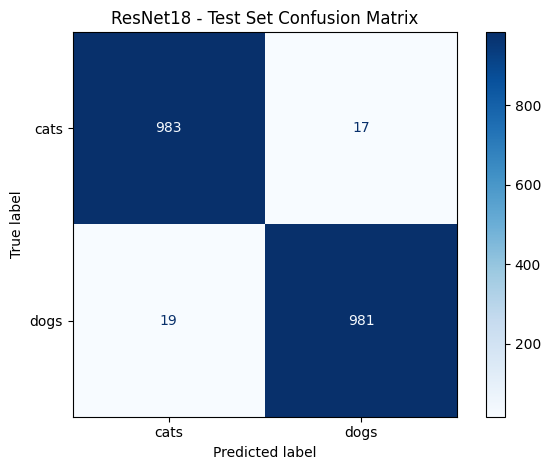

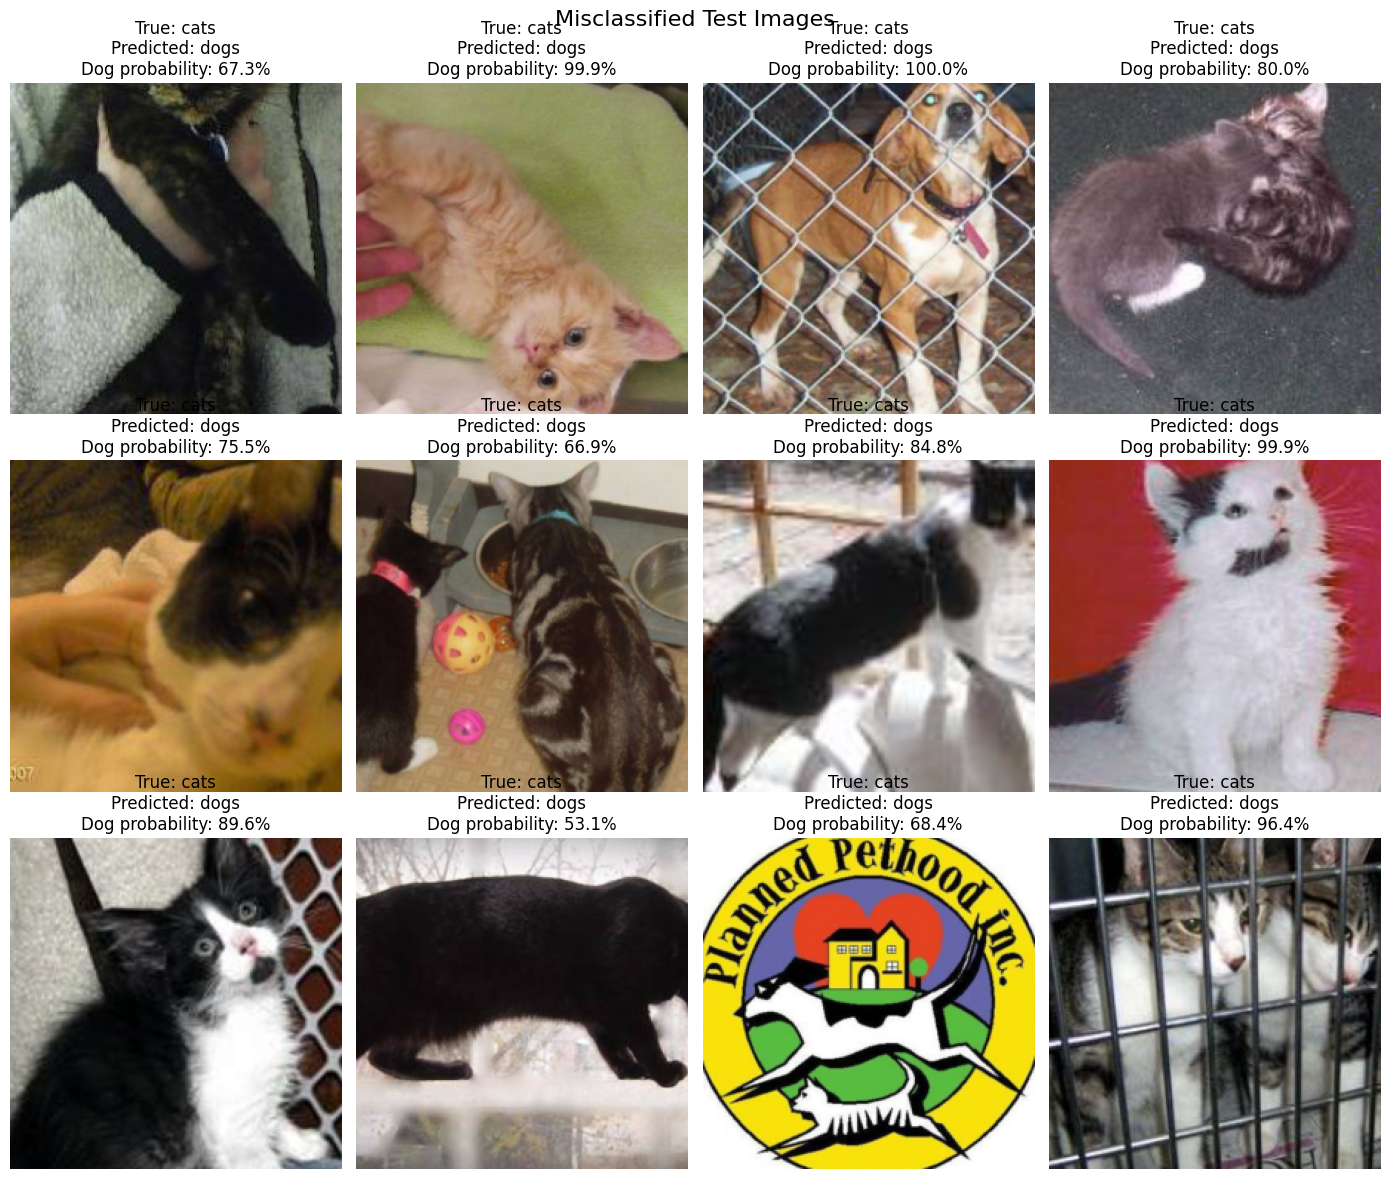

In [23]:

import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. LOAD BEST RESNET18 CHECKPOINT
# ==========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_resnet.load_state_dict(
    torch.load(
        "/kaggle/working/resnet18_transfer/best_resnet18.pth",
        map_location=device,
        weights_only=True
    )
)

model_resnet = model_resnet.to(device)
model_resnet.eval()

# ==========================================
# 2. CREATE TEST DATASET
# ==========================================

# Use the same deterministic ImageNet transform as validation.
test_transform_resnet = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset_resnet = datasets.ImageFolder(
    test_path,
    transform=test_transform_resnet
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

class_names = test_dataset_resnet.classes
print("Classes:", class_names)
print("Test images:", len(test_dataset_resnet))

# ==========================================
# 3. PREDICT ON TEST SET
# ==========================================

all_labels = []
all_preds = []
all_probs = []
misclassified = []

with torch.no_grad():
    for images, labels in test_loader_resnet:
        images_device = images.to(device, non_blocking=True)

        logits = model_resnet(images_device).squeeze(1)
        probabilities = torch.sigmoid(logits)
        predictions = (logits >= 0).long()

        all_labels.extend(labels.numpy().tolist())
        all_preds.extend(predictions.cpu().numpy().tolist())
        all_probs.extend(probabilities.cpu().numpy().tolist())

        # Keep a few errors for visualization
        wrong_indices = (predictions.cpu() != labels).nonzero(
            as_tuple=True
        )[0]

        for idx in wrong_indices.tolist():
            if len(misclassified) < 12:
                misclassified.append((
                    images[idx].cpu().clone(),
                    int(labels[idx]),
                    int(predictions[idx]),
                    float(probabilities[idx])
                ))

# ==========================================
# 4. CALCULATE METRICS
# ==========================================

test_accuracy = accuracy_score(all_labels, all_preds)

test_precision = precision_score(
    all_labels, all_preds, zero_division=0
)
test_recall = recall_score(
    all_labels, all_preds, zero_division=0
)
test_f1 = f1_score(
    all_labels, all_preds, zero_division=0
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall   : {test_recall:.4f}")
print(f"Test F1-score : {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# ==========================================
# 5. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()

# ==========================================
# 6. DISPLAY MISCLASSIFIED IMAGES
# ==========================================

if not misclassified:
    print("No misclassified images found!")
else:
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    n = len(misclassified)
    cols = 4
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(
        rows, cols, figsize=(14, 4 * rows)
    )
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for i, (img, true_label, pred_label, dog_prob) in enumerate(
        misclassified
    ):
        img = img * std + mean
        img = img.clamp(0, 1).permute(1, 2, 0).numpy()

        axes[i].imshow(img)
        axes[i].set_title(
            f"True: {class_names[true_label]}\n"
            f"Predicted: {class_names[pred_label]}\n"
            f"Dog probability: {dog_prob:.1%}"
        )
        axes[i].axis("off")

    plt.suptitle("Misclassified Test Images", fontsize=16)
    plt.tight_layout()
    plt.show()

Image: cat_or_dog_1.jpg
Prediction: dogs
Model confidence: 100.00%


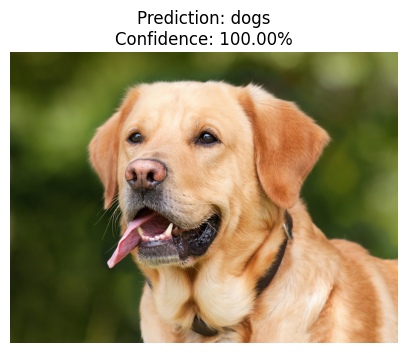

----------------------------------------
Image: cat_or_dog_2.jpg
Prediction: cats
Model confidence: 99.98%


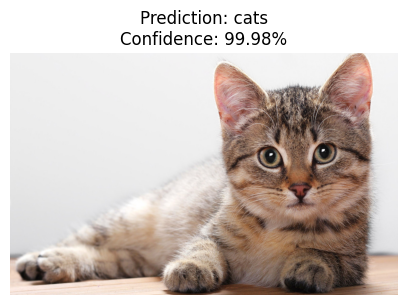

----------------------------------------
Metadata saved: /kaggle/working/resnet18_transfer/metadata.json


In [24]:

import os
import json
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

# ==========================================
# 1. INFERENCE SETUP
# ==========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_resnet.load_state_dict(
    torch.load(
        "/kaggle/working/resnet18_transfer/best_resnet18.pth",
        map_location=device,
        weights_only=True
    )
)

model_resnet = model_resnet.to(device)
model_resnet.eval()

class_names = ["cats", "dogs"]

inference_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ==========================================
# 2. PREDICTION FUNCTION
# ==========================================

def predict_cat_or_dog(image_path):
    image = Image.open(image_path).convert("RGB")
    input_tensor = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logit = model_resnet(input_tensor).squeeze()
        dog_probability = torch.sigmoid(logit).item()

    predicted_index = 1 if dog_probability >= 0.5 else 0
    confidence = (
        dog_probability
        if predicted_index == 1
        else 1 - dog_probability
    )

    print("Image:", os.path.basename(image_path))
    print("Prediction:", class_names[predicted_index])
    print(f"Model confidence: {confidence * 100:.2f}%")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Prediction: {class_names[predicted_index]}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    return {
        "image": image_path,
        "prediction": class_names[predicted_index],
        "confidence": round(confidence, 4)
    }

# ==========================================
# 3. TEST THE FUNCTION ON SAMPLE IMAGES
# ==========================================

single_prediction_path = os.path.join(
    dataset_path, "single_prediction"
)

sample_images = [
    os.path.join(single_prediction_path, filename)
    for filename in os.listdir(single_prediction_path)
    if filename.lower().endswith((".jpg", ".jpeg", ".png"))
]

if sample_images:
    for image_path in sample_images:
        result = predict_cat_or_dog(image_path)
        print("-" * 40)
else:
    print("No sample images found in:", single_prediction_path)

# ==========================================
# 4. SAVE MODEL METADATA
# ==========================================

metadata = {
    "architecture": "ResNet18",
    "pretrained_weights": "ImageNet",
    "classes": class_names,
    "input_size": [224, 224],
    "normalization_mean": [0.485, 0.456, 0.406],
    "normalization_std": [0.229, 0.224, 0.225],
    "checkpoint": "best_resnet18.pth"
}

metadata_path = "/kaggle/working/resnet18_transfer/metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved:", metadata_path)

AssertionError: Checkpoint nahi mila: /kaggle/working/resnet18_transfer/best_resnet18.pth